In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import pandas as pd
import skimage as ski
import tifffile as tif
from scipy.spatial import KDTree
import scanpy as sc
import spatialdata as sd
import spatialdata_plot  


## Load Visium HD and spatial ATAC-seq barcode position files

In [2]:
visium_coords = pd.read_csv("./63511_8um_tissue_positions.csv", index_col=0)
visium_coords

,in_tissue,array_row,array_col,pxl_row_in_fullres,pxl_col_in_fullres
barcode,,,,,
s_008um_00000_00000-1,0,0,0,6128.253022,728.276833
s_008um_00000_00001-1,0,0,1,6128.219382,735.840180
s_008um_00000_00002-1,0,0,2,6128.185742,743.403527
s_008um_00000_00003-1,0,0,3,6128.152102,750.966874
s_008um_00000_00004-1,0,0,4,6128.118462,758.530220
...,...,...,...,...,...
s_008um_00837_00833-1,0,837,833,-230.218272,7000.310678
s_008um_00837_00834-1,0,837,834,-230.251804,7007.873663
s_008um_00837_00835-1,0,837,835,-230.285335,7015.436648


In [3]:
atac_coords = pd.read_csv("./63511_tissue_positions_list.csv", index_col=0, header=None)
atac_coords

,1,2,3,4,5
0,,,,,
AACGTGATAACGTGAT,0,0,0,428,617
AACGTGATGCGAGTAA,0,1,0,452,617
AACGTGATATGCCTAA,0,2,0,476,617
AACGTGATGCTAACGA,0,3,0,500,617
AACGTGATACCACTGT,0,4,0,524,617
...,...,...,...,...,...
ATGCAACCAGGTGTTG,0,215,219,5612,5942
ATGCAACCTTGCCTTG,0,216,219,5637,5942
ATGCAACCAGTCCTTG,0,217,219,5661,5942


## Load Visium HD and spatial ATAC-seq images

In [4]:
atac = tif.imread("./63511_ATAC.tif")
visium = tif.imread("./63511_Visium_HE.tiff")

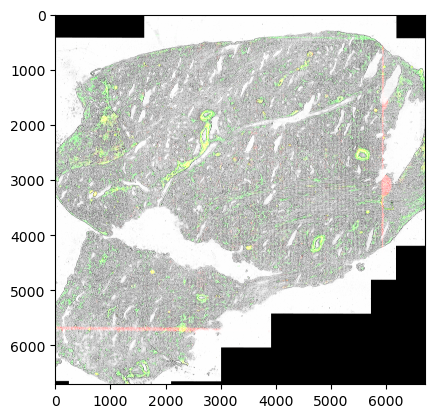

In [5]:
plt.imshow(atac, cmap="gray")

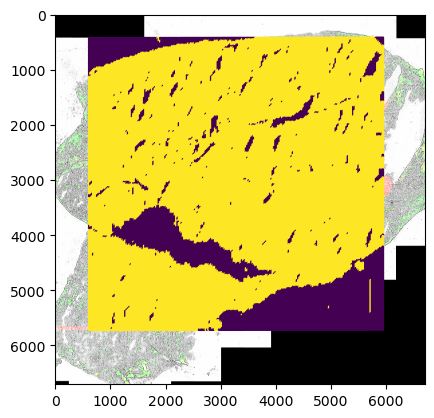

In [6]:
plt.imshow(atac, cmap="gray")
plt.scatter(atac_coords[5], atac_coords[4], c=atac_coords[1], s=1)

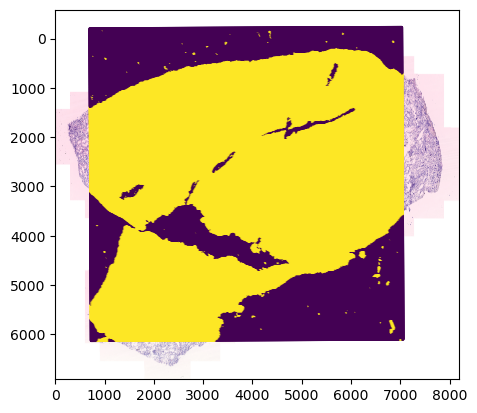

In [8]:
plt.imshow(visium, cmap="gray")
plt.scatter(
    visium_coords["pxl_col_in_fullres"],
    visium_coords["pxl_row_in_fullres"],
    c=visium_coords["in_tissue"],
    s=1,
)

## Load landmark file

In [5]:
def load_landmarks(landmark_file):
    """
    Load landmarks from various file formats
    Expected format: each row contains corresponding points
    For 2D: moving_x, moving_y, target_x, target_y
    For 3D: moving_x, moving_y, moving_z, target_x, target_y, target_z
    """
    if landmark_file.suffix.lower() == ".csv":
        data = pd.read_csv(landmark_file, header=None)
    else:
        # Try to read as space/tab separated
        data = pd.read_csv(landmark_file, sep=None, engine="python", header=None)

    data = data.iloc[:, 2:]
    # Convert to numpy array
    landmarks = data.values

    # Determine if 2D or 3D based on number of columns
    if landmarks.shape[1] == 4:  # 2D
        source = landmarks[:, :2]
        target = landmarks[:, 2:]
    elif landmarks.shape[1] == 6:  # 3D
        source = landmarks[:, :3]
        target = landmarks[:, 3:]
    else:
        raise ValueError(
            f"Unexpected number of columns in landmarks file: {landmarks.shape[1]}"
        )

    return source, target

In [ ]:
target, source = load_landmarks(Path("./63511_landmarks.csv"))
source_px = source / 84.6667
target_px = target / 84.6667

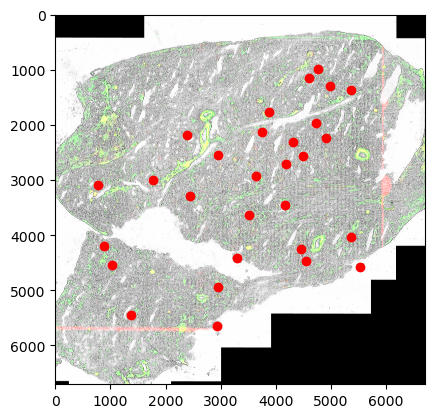

In [7]:
plt.imshow(atac, cmap="gray")
plt.scatter(source_px[:, 0], source_px[:, 1], color="red")

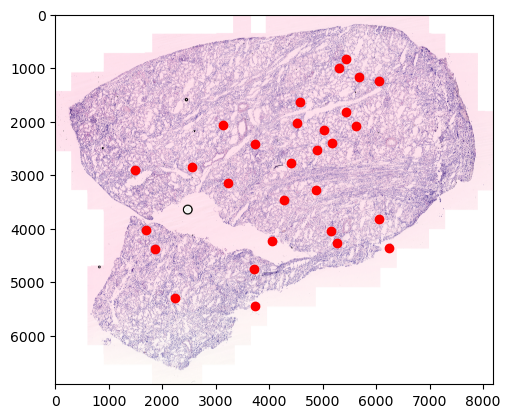

In [8]:
plt.imshow(visium, cmap="gray")
plt.scatter(target_px[:, 0], target_px[:, 1], color="red")

## Perform TPS transform

In [10]:
tps = ski.transform.ThinPlateSplineTransform()
tps.estimate(target_px, source_px)

/tmp/ipykernel_3228390/907915464.py:2: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `ThinPlateSplineTransform.from_estimate` class constructor instead.
  tps.estimate(target_px, source_px)


True

In [11]:
old_coords = visium_coords[["pxl_col_in_fullres", "pxl_row_in_fullres"]].values
new_coords = tps(old_coords)
visium_coords["aligned_row"] = new_coords[:, 1]
visium_coords["aligned_col"] = new_coords[:, 0]

In [15]:
visium_coords

,in_tissue,array_row,array_col,pxl_row_in_fullres,pxl_col_in_fullres,aligned_row,aligned_col
barcode,,,,,,,
s_008um_00000_00000-1,0,0,0,6128.253022,728.276833,6286.677342,-170.595504
s_008um_00000_00001-1,0,0,1,6128.219382,735.840180,6286.583114,-163.059048
s_008um_00000_00002-1,0,0,2,6128.185742,743.403527,6286.489152,-155.521979
s_008um_00000_00003-1,0,0,3,6128.152102,750.966874,6286.395459,-147.984289
s_008um_00000_00004-1,0,0,4,6128.118462,758.530220,6286.302039,-140.445973
...,...,...,...,...,...,...,...
s_008um_00837_00833-1,0,837,833,-230.218272,7000.310678,-92.214188,6417.112523
s_008um_00837_00834-1,0,837,834,-230.251804,7007.873663,-92.210748,6424.704108
s_008um_00837_00835-1,0,837,835,-230.285335,7015.436648,-92.206818,6432.296244


Text(0.5, 1.0, 'Aligned Visium spots on ATAC image')

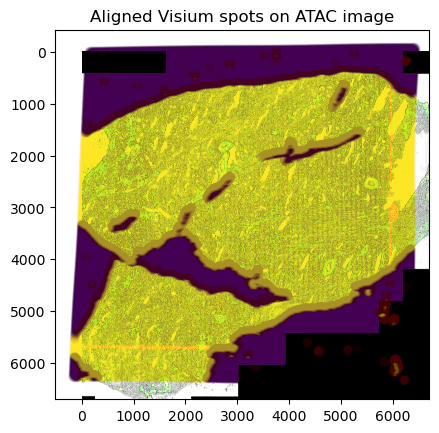

In [19]:
plt.imshow(atac, cmap="gray")
plt.scatter(
    visium_coords["aligned_col"],
    visium_coords["aligned_row"],
    c=visium_coords["in_tissue"],
    alpha=0.01,
)
plt.title("Aligned Visium spots on ATAC image")

In [17]:
visium_coords = visium_coords.rename(columns={"aligned_row": "y", "aligned_col": "x"})
atac_coords = atac_coords.rename(columns={4: "y", 5: "x"})

## Overlap Visium HD 8µm bin and spATAC-seq barcodes after TPS transform

In [18]:
def find_all_grid_overlaps_kdtree(df_a, df_b, size_a=15, size_b=8):
    """
    Finds overlaps between squares in df_b and df_a.
    Returns df_b with a new column "overlap_indices" containing a LIST of
    overlapping indices from df_a.

    The index of df_b remains unique.
    """

    coords_a = df_a[["x", "y"]].values
    coords_b = df_b[["x", "y"]].values

    # We use the diagonal (hypotenuse) to account for rotation (TPS distortion).
    radius_a = np.sqrt((size_a / 2) ** 2 + (size_a / 2) ** 2)
    radius_b = np.sqrt((size_b / 2) ** 2 + (size_b / 2) ** 2)
    search_radius = radius_a + radius_b

    print(f"Building KD-Tree on {len(df_a)} points...")
    tree = KDTree(coords_a)

    print(f"Querying neighbors within Euclidean radius {search_radius:.2f}...")
    # p=2 -> Euclidean distance
    indices_lists = tree.query_ball_point(coords_b, r=search_radius, p=2)

    df_a_indices = df_a.index.to_numpy()

    # This creates a list of lists: [[Label1, Label2], [Label1], [], ...]
    overlap_labels = [
        [df_a_indices[i] for i in positional_list] for positional_list in indices_lists
    ]

    result_df = df_b.copy()

    result_df["overlap_indices"] = overlap_labels

    result_df["overlap_count"] = result_df["overlap_indices"].apply(len)

    print("Processing complete.")
    return result_df

In [19]:
res = find_all_grid_overlaps_kdtree(atac_coords, visium_coords, size_a=15, size_b=8)

Building KD-Tree on 48400 points...
Querying neighbors within Euclidean radius 16.26...
Processing complete.


In [20]:
res

,in_tissue,array_row,array_col,pxl_row_in_fullres,pxl_col_in_fullres,y,x,overlap_indices,overlap_count
barcode,,,,,,,,,
s_008um_00000_00000-1,0,0,0,6128.253022,728.276833,6286.677342,-170.595504,[],0
s_008um_00000_00001-1,0,0,1,6128.219382,735.840180,6286.583114,-163.059048,[],0
s_008um_00000_00002-1,0,0,2,6128.185742,743.403527,6286.489152,-155.521979,[],0
s_008um_00000_00003-1,0,0,3,6128.152102,750.966874,6286.395459,-147.984289,[],0
s_008um_00000_00004-1,0,0,4,6128.118462,758.530220,6286.302039,-140.445973,[],0
...,...,...,...,...,...,...,...,...,...
s_008um_00837_00833-1,0,837,833,-230.218272,7000.310678,-92.214188,6417.112523,[],0
s_008um_00837_00834-1,0,837,834,-230.251804,7007.873663,-92.210748,6424.704108,[],0
s_008um_00837_00835-1,0,837,835,-230.285335,7015.436648,-92.206818,6432.296244,[],0


In [21]:
res.overlap_count.value_counts()

overlap_count
1    282782
0    214565
2    204897
Name: count, dtype: int64

In [22]:
res.to_csv("./visium_atac_overlaps_2026-01-12.csv")

## Covert 8µm bin to cell_id in Visium HD data

In [ ]:
bins_adata = sc.read_10x_h5("/beegfs/data/CostaLab/Spatial_ATAC_Analysis_KuppeLab/data/raw/VisiumHD/Visium_HD_63511/outs/binned_outputs/square_008um/filtered_feature_bc_matrix.h5")
pos = pd.read_parquet("/beegfs/data/CostaLab/Spatial_ATAC_Analysis_KuppeLab/data/raw/VisiumHD/Visium_HD_63511/outs/binned_outputs/square_008um/spatial/tissue_positions.parquet")
pos = pos.set_index("barcode")

bins_adata.obs = bins_adata.obs.join(pos)

sdata = sdata = sd.read_zarr("/beegfs/data/CostaLab/Spatial_ATAC_Analysis_KuppeLab/src/preprocessing/RNA/Visium_HD/analysis/zarr/63511")
print(sdata)

In [ ]:
import geopandas as gpd
from shapely.geometry import Point

bins_gdf = gpd.GeoDataFrame(
    bins_adata.obs,
    geometry=gpd.points_from_xy(
        bins_adata.obs["pxl_col_in_fullres"],
        bins_adata.obs["pxl_row_in_fullres"]
    ),
    crs=sdata.shapes["63511_cell_boundaries"].crs
)

In [ ]:
cells = sdata.shapes["63511_cell_boundaries"]

matched = gpd.sjoin(
    bins_gdf,
    cells[["geometry"]],
    how="left",
    predicate="within"
)

matched.head()

In [ ]:
matched["cell_id"] = matched.index_right
cell_barcode_map = matched[["cell_id"]]
cell_barcode_map.head()
cell_barcode_map.to_csv("barcode_cell_id.csv")


In [ ]:
filter_cell_barcode_map = cell_barcode_map[cell_barcode_map["cell_id"].notna()]
filter_cell_barcode_map.index.name = "barcode"
filter_cell_barcode_map = filter_cell_barcode_map.reset_index()
filter_cell_barcode_map.columns =["barcode","cell_id"]
filter_cell_barcode_map.head()
filter_cell_barcode_map.to_csv("filter_barcode_cell_id.csv")

## overlap cell_id from Visium HD and barcode from spATAC-seq

In [ ]:
overlap_df = pd.read_csv("./visium_atac_overlaps_2026-01-12.csv")
filter_overlap_df = overlap_df[overlap_df["overlap_count"] != 0]
filter_overlap_df.to_csv("filtered_overlap.csv", index=False)
final_df = pd.merge(filter_overlap_df, filter_cell_barcode_map, on="barcode", how="inner")